# Spectral Estimation

**Reference:** Shumway, R. H., and Stoffer, D. S. (2019). *Time Series: A Data Analysis Approach Using R*. Chapman & Hall/CRC.

**Topics:** discrete Fourier transform, periodogram, uncertainty, smoothed spectral estimation, tapering, autoregressive spectra, cross-spectra, and coherence.

## R packages and data

The `astsa` package provides `soi`, `rec`, `mvspec()`, `tsplot()`, and `Grid()`. The remaining calculations use standard R functions from `stats` and `graphics`. Run the notebook in **Google Colab with the R runtime**. Package installation is only needed when it is absent from the current runtime.

In [1]:
if (!requireNamespace("astsa", quietly=TRUE)) {
  install.packages("astsa", repos="https://cloud.r-project.org")
}
library(astsa)
options(digits=6)
par(mfrow=c(1,1))
cat("SOI observations:", length(soi), "| Recruitment observations:", length(rec), "\n")
cat("SOI observations per year:", frequency(soi), "\n")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



SOI observations: 453 | Recruitment observations: 453 
SOI observations per year: 12 


## 1. Discrete Fourier transform (DFT) and inverse DFT

For a sample $x_1,\ldots,x_n$, the Fourier frequencies are $\omega_j=j/n$ (cycles per observation). The DFT and its inverse are

$$
\boxed{d(\omega_j)=\frac{1}{\sqrt n}\sum_{t=1}^{n}x_t e^{-2\pi i\omega_jt}},\qquad j=0,\ldots,n-1,
$$

$$
\boxed{x_t=\frac{1}{\sqrt n}\sum_{j=0}^{n-1}d(\omega_j)e^{2\pi i\omega_jt}}.
$$

Here $i^2=-1$ and $e^{i\theta}=\cos\theta+i\sin\theta$. The **real part** measures alignment with cosine, while the **negative imaginary part** measures alignment with sine. The FFT (`fft()`) computes the DFT efficiently, without changing the mathematical result. R's `fft()` is *unnormalized*, so the factor $1/\sqrt n$ must be supplied in both forward and inverse transforms.

In [2]:
x = 1:4
n = length(x)
(dft = fft(x)/sqrt(n))
(idft = fft(dft, inverse=TRUE)/sqrt(n))
cat("Maximum reconstruction error:", max(abs(Re(idft)-x)), "\n")

[1]  5+0i -1+1i -1+0i -1-1i

[1] 1+0i 2+0i 3+0i 4+0i

Maximum reconstruction error: 0 


### Worked DFT calculation

For $x=(1,2,3,4)$, $n=4$ and the normalized zero-frequency coefficient is

$$d(0)=\frac{1+2+3+4}{\sqrt4}=5.$$

At $\omega_1=1/4$, using $e^{-2\pi i t/4}=(-i,-1,i,1)$ for $t=1,2,3,4$,

$$d(1/4)=\frac{-i-2+3i+4}{2}=1+i.$$

**Important indexing detail:** R computes the FFT using indices $t=0,\ldots,n-1$, whereas the displayed theoretical definition uses $t=1,\ldots,n$. This shifts the *phase* of nonzero Fourier coefficients, but **not their squared magnitudes**, inverse reconstruction, or periodogram. For this R result, the coefficient at $j=1$ is $-1+i$ instead of $1+i$; both have $|d|^2=2$.

The inverse should reconstruct $(1,2,3,4)$ to floating-point precision; a tiny error (about $10^{-15}$) is numerical rounding rather than an imperfect Fourier representation.

## 2. Cosine and sine transforms

Write

$$d(\omega_j)=d_c(\omega_j)-i\,d_s(\omega_j),$$

$$d_c(\omega_j)=\frac1{\sqrt n}\sum_{t=1}^n x_t\cos(2\pi\omega_jt),\quad
 d_s(\omega_j)=\frac1{\sqrt n}\sum_{t=1}^n x_t\sin(2\pi\omega_jt).$$

Consequently,

$$\boxed{I(\omega_j)=|d(\omega_j)|^2=d_c^2(\omega_j)+d_s^2(\omega_j)}.$$

At ordinary interior frequencies, under appropriate short-memory and regularity assumptions, the two transforms are approximately independent normals, each with variance $f(\omega_j)/2$. Such distributional approximations do **not** generally become exact merely because a finite sample comes from an arbitrary Gaussian stationary process.

In [3]:
j = 1
omega = j/n
t = 1:n
dc = sum(x*cos(2*pi*omega*t))/sqrt(n)
ds = sum(x*sin(2*pi*omega*t))/sqrt(n)
cat("Cosine transform (t=1 index):", dc, "\n")
cat("Sine transform (t=1 index):", ds, "\n")
cat("Periodogram (direct):", dc^2+ds^2, "\n")
cat("Periodogram (FFT):", Mod(dft[j+1])^2, "\n")

Cosine transform (t=1 index): 1 
Sine transform (t=1 index): -1 
Periodogram (direct): 2 
Periodogram (FFT): 2 


## 3. The periodogram

The **periodogram** measures the strength of oscillations at the Fourier frequencies:

$$\boxed{I(\omega_j)=\left|n^{-1/2}\sum_{t=1}^n x_t e^{-2\pi i\omega_j t}\right|^2}.$$

At zero frequency, $I(0)=n\bar x^2$. A nonzero mean can therefore produce a large spike unrelated to cycles. Centering $x_t-\bar x$ removes this zero-frequency spike; linear detrending may also be useful when an increasing or decreasing baseline dominates the low-frequency spectrum.

For real data, $I(\omega_j)=I(1-\omega_j)$, so frequencies above $0.5$ cycles per observation are mirror images of lower frequencies. One usually plots only $0\leq\omega\leq0.5$. A peak at frequency $\omega$ corresponds to a period $T=1/\omega$ observations per cycle.

In [4]:
z = x-mean(x)
I = Mod(fft(z)/sqrt(length(z)))^2
print(data.frame(j=0:(n-1), frequency=(0:(n-1))/n, periodogram=I))
cat("Zero-frequency power after centering:", I[1], "\n")

  j frequency periodogram
1 0      0.00           0
2 1      0.25           2
3 2      0.50           1
4 3      0.75           2
Zero-frequency power after centering: 0 


### Numerical interpretation

A larger periodogram ordinate means **more sample power at that frequency**, but it does not independently prove the presence of a stable physical oscillation. A raw periodogram is highly variable even when the underlying spectrum is smooth. Smoothing and uncertainty assessment are needed to distinguish broad, reproducible spectral structure from random spikes.

## 4. Why the raw periodogram is noisy

For an ordinary interior Fourier frequency under regularity assumptions,

$$\frac{2I(\omega_j)}{f(\omega_j)}\overset{\cdot}{\sim}\chi^2_2,$$

where $f(\omega)$ is the **population spectral density**, and $\chi^2_2$ is a chi-square random variable with 2 degrees of freedom. Thus,

$$E[I(\omega_j)]\approx f(\omega_j),\qquad
\boxed{\operatorname{Var}[I(\omega_j)]\approx f^2(\omega_j)}.$$

The variance **does not approach zero** simply by increasing $n$: the unsmoothed periodogram is not a consistent pointwise spectral-density estimator. This is different from a sample mean, whose variance usually decreases like $1/n$.

An approximate 95% interval from a single periodogram ordinate is

$$\left[\frac{2I(\omega_j)}{\chi^2_{2,0.975}},\frac{2I(\omega_j)}{\chi^2_{2,0.025}}\right].$$

Here $\chi^2_{\nu,p}$ denotes the lower-tail $p$ quantile with $\nu$ degrees of freedom. The upper bound can be extremely large when $\nu=2$.

Theoretical white-noise spectrum: 1
Raw periodogram mean, nonzero interior frequencies: 1.01038 
Raw periodogram SD, nonzero interior frequencies: 1.03618 


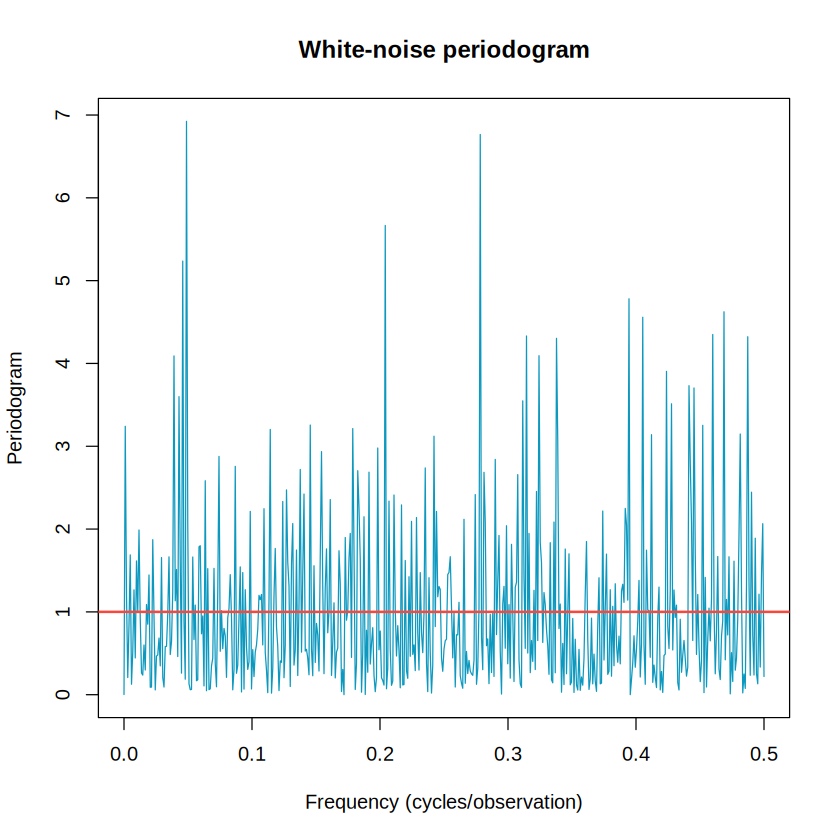

In [5]:
set.seed(7201)
u = rnorm(2^10)
U = fft(u)/sqrt(length(u))
freq = (0:(length(u)/2))/length(u)
Iu = Mod(U[1:(length(u)/2+1)])^2
par(mfrow=c(1,1))
plot(freq, Iu, type="l", col=rgb(.05,.6,.75), xlab="Frequency (cycles/observation)",
     ylab="Periodogram", main="White-noise periodogram")
abline(h=1, col=2, lwd=2)
cat("Theoretical white-noise spectrum: 1\n")
cat("Raw periodogram mean, nonzero interior frequencies:", mean(Iu[2:512]), "\n")
cat("Raw periodogram SD, nonzero interior frequencies:", sd(Iu[2:512]), "\n")

**Graph interpretation:** The horizontal red line is the theoretical spectral density $f(\omega)=1$ of unit-variance white noise. Although the true spectrum is flat, random spikes across the blue periodogram can be tall. The observed mean and SD printed by R are **sample results**, whereas theoretical approximate mean and SD are both 1. Their disagreement in a single sample does not imply that the simulated white noise has true periodicity.

**Observed result:** The 1024-point simulation gives a mean periodogram ordinate of **1.01038** and an SD of **1.03618** across the 511 nonzero interior frequencies. These are near the theoretical white-noise mean and SD of **1**, despite prominent individual spikes. Peaks in one white-noise realization therefore should not be interpreted automatically as genuine cycles.

## 5. Uncertainty at a single frequency

Let $I_j=I(\omega_j)$. The chi-square interval is strongly asymmetric because $I_j$ is positive and its distribution is skewed. A log-scale representation makes this clearer:

$$\log f(\omega_j)\in\left[
\log I_j+\log 2-\log\chi^2_{2,0.975},\;
\log I_j+\log2-\log\chi^2_{2,0.025}\right].$$

These are approximate **pointwise** intervals, not simultaneous confidence bands across all tested frequencies.

**Numerical implication:** The next calculation is an example of why unsmoothed spectral inference is imprecise, even when the periodogram happens to be small at the selected frequency.

**Executed numerical example (at $\omega=0.0625$):** $I=0.10634$ produces a 95% interval **$[0.0288271,\;4.2002]$**, with upper-to-lower ratio **145.703**. The true flat white-noise spectrum $f=1$ is inside the interval. This large range makes an isolated periodogram ordinate a weak basis for inferring spectral density.

In [6]:
freq_index = 64
I_j = Iu[freq_index+1]
CI = c(2*I_j/qchisq(.975,df=2), 2*I_j/qchisq(.025,df=2))
cat("Frequency:", freq[freq_index+1], "cycles/observation\n")
cat("Observed periodogram:", I_j, "\n")
cat("Approximate 95% pointwise spectrum interval:", CI, "\n")
cat("Interval upper/lower ratio:", CI[2]/CI[1], "\n")

Frequency: 0.0625 cycles/observation
Observed periodogram: 0.10634 
Approximate 95% pointwise spectrum interval: 0.0288271 4.2002 
Interval upper/lower ratio: 145.703 


## 6. Zero-padding and physical frequency units

For a monthly series with $n=453$, the `nextn()` function provides a computationally convenient FFT length. **Zero-padding does not add observations or improve intrinsic frequency resolution**; it produces a denser numerical frequency grid. The frequency units displayed by `mvspec()` for a monthly `ts` object are **cycles per year** (0 to 6), rather than cycles per month (0 to 0.5).

The conversion is

$$\omega_{\mathrm{year}}=12\,\omega_{\mathrm{month}}.$$

Thus $\omega=1$ cycle/year corresponds to a 12-month period, and $\omega=0.25$ cycles/year corresponds to a 4-year or 48-month period.

**Interpretation of zero padding:** Extending 453 observations to 480 FFT positions refines the sampled frequency grid; it does **not** create 27 additional observations or improve the underlying frequency resolution by itself.

In [7]:
cat("Original monthly series length:", length(soi), "\n")
cat("Next efficient FFT length:", nextn(length(soi)), "\n")
cat("Annual cycle (cycles/year):", 1, "| period (months):", 12, "\n")
cat("Four-year cycle (cycles/year):", 1/4, "| period (months):", 48, "\n")

Original monthly series length: 453 
Next efficient FFT length: 480 
Annual cycle (cycles/year): 1 | period (months): 12 
Four-year cycle (cycles/year): 0.25 | period (months): 48 


## 7. SOI and Recruitment: raw periodograms

The Southern Oscillation Index (`soi`) and Recruitment (`rec`) are monthly observations. Spectral power at approximately **1 cycle/year** indicates the annual oscillation. Broader energy in the **1/7 to 1/3 cycles/year** band corresponds to cycles lasting approximately **3–7 years**. A broad low-frequency peak suggests an irregular timescale rather than a perfectly repeating four-year sinusoid.

The shaded region highlights the 3–7-year band and the dotted line marks four years.

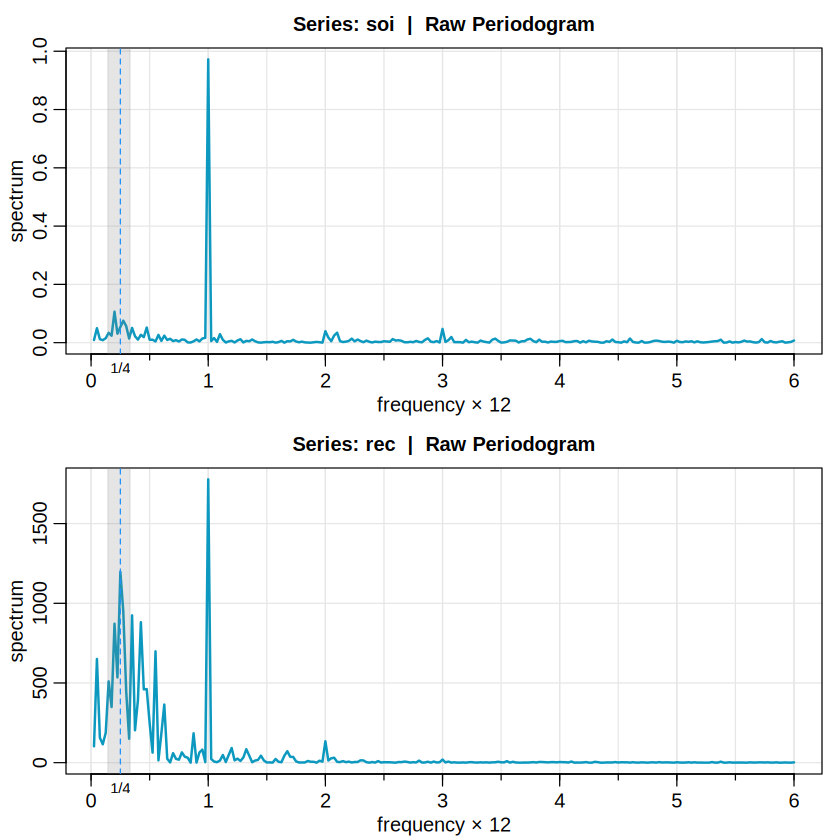

In [8]:
par(mfrow=c(2,1))
soi_raw = mvspec(soi, col=rgb(.05,.6,.75), lwd=2)
rect(1/7,-1e5,1/3,1e5, density=NA, col=gray(.5,.2))
abline(v=1/4,lty=2,col="dodgerblue")
mtext("1/4", side=1, line=0, at=.25, cex=.75)
rec_raw = mvspec(rec, col=rgb(.05,.6,.75), lwd=2)
rect(1/7,-1e5,1/3,1e5, density=NA, col=gray(.5,.2))
abline(v=1/4,lty=2,col="dodgerblue")
mtext("1/4", side=1, line=0, at=.25, cex=.75)
par(mfrow=c(1,1))

**What to examine in each graph:** The horizontal axis is cycles/year, and the vertical axis is spectral power on the plotting scale used by `mvspec()`. Locate the annual peak around 1, then compare the breadth of the peaks in the highlighted multi-year band. Do not interpret one isolated narrow raw-periodogram ordinate as a statistically established cycle. These two spectra also have different vertical scales, so peak heights must not be compared without checking the axes.

## 8. Log-periodograms and asymmetry of uncertainty

Using `log="yes"` produces a log-scaled spectral plot. It helps reveal relatively small peaks alongside a much larger annual peak. Because a single ordinate has approximately 2 degrees of freedom, its generic 95% interval remains wide; changing the axis scale does not make the estimator more precise.

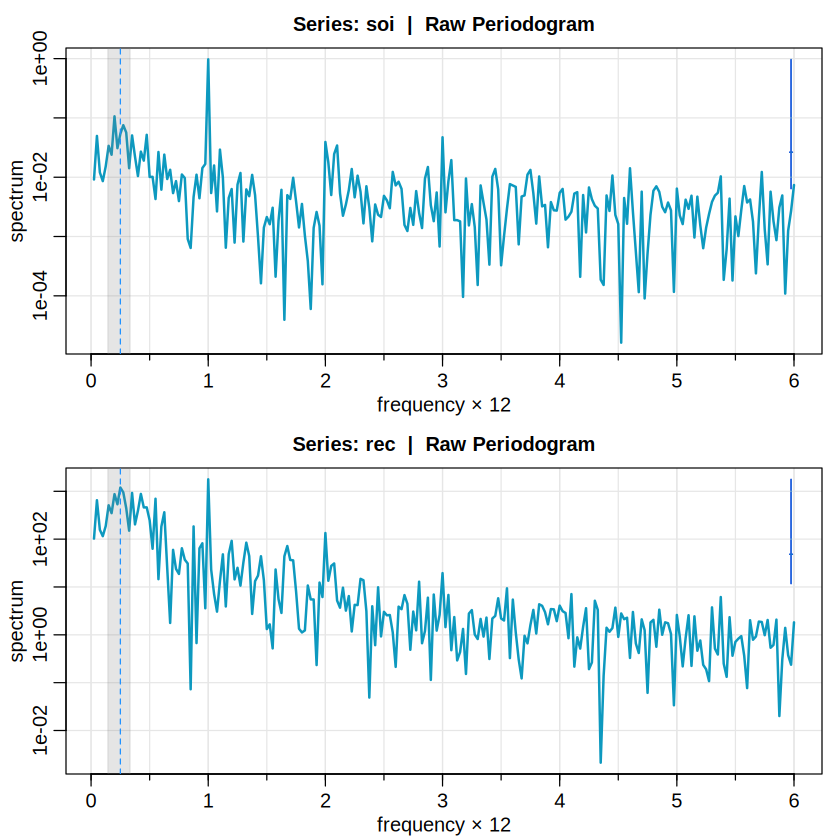

In [9]:
par(mfrow=c(2,1))
mvspec(soi, log="yes", col=rgb(.05,.6,.75), lwd=2)
rect(1/7,1e-5,1/3,1e5, density=NA, col=gray(.5,.2))
abline(v=.25, lty=2, col="dodgerblue")
mvspec(rec, log="yes", col=rgb(.05,.6,.75), lwd=2)
rect(1/7,1e-5,1/3,1e5, density=NA, col=gray(.5,.2))
abline(v=.25, lty=2, col="dodgerblue")
par(mfrow=c(1,1))

## 9. Smoothed periodogram: averaging neighboring frequencies

A frequency band with $L=2m+1$ Fourier ordinates can be smoothed by the local average

$$\boxed{\bar f(\omega_j)=\frac1L\sum_{k=-m}^{m}I(\omega_j+k/n)}.$$

If $f$ changes little across this band and the ordinates are approximately independent,

$$\frac{2L\bar f(\omega)}{f(\omega)}\overset{\cdot}{\sim}\chi^2_{2L},\qquad
E[\bar f(\omega)]\approx f(\omega),\qquad
\operatorname{Var}[\bar f(\omega)]\approx\frac{f^2(\omega)}{L}.$$

**Bandwidth:** $B=L/n$ cycles/observation. Increasing $L$ averages more frequencies, lowering variance but potentially flattening real narrow peaks. Decreasing $L$ preserves resolution but gives noisier estimates. This is the fundamental **bias–variance (resolution–stability) trade-off**.

Raw SD across displayed ordinates: 1.03618 
Smoothed SD across displayed ordinates: 0.0632526 


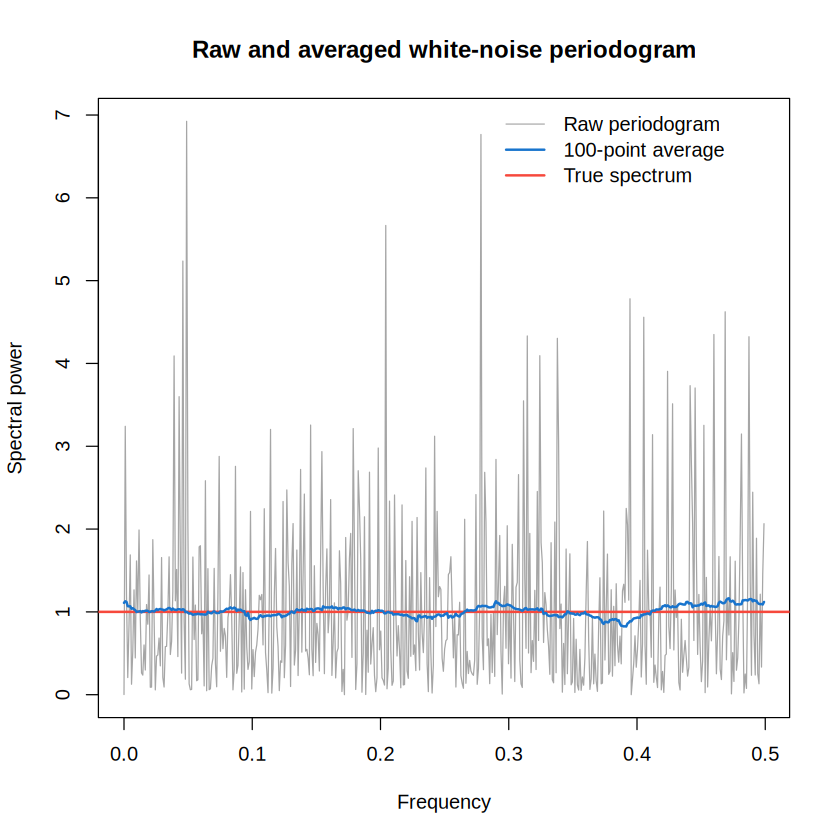

In [10]:
z = Mod(fft(u)/sqrt(length(u)))^2
z_smoothed = filter(z, filter=rep(.01,100), circular=TRUE)
w = (0:511)/1024
plot(w, z[1:512], type="l", col=gray(.65), xlab="Frequency", ylab="Spectral power",
     main="Raw and averaged white-noise periodogram")
abline(h=1, col=2, lwd=2)
lines(w, z_smoothed[1:512], col=4, lwd=2)
legend("topright", c("Raw periodogram", "100-point average", "True spectrum"),
       col=c(gray(.65),4,2), lty=1, lwd=c(1,2,2), bty="n")
cat("Raw SD across displayed ordinates:", sd(z[2:512]), "\n")
cat("Smoothed SD across displayed ordinates:", sd(as.numeric(z_smoothed[2:512])), "\n")

**Interpretation:** The 100-point average is expected to be less jagged than the raw periodogram because neighboring frequency powers are pooled. Here `circular=TRUE` uses periodic extension at the boundaries, which is convenient for the full FFT grid; edge treatment matters in practical smoothing. The plotted SDs quantify variation *across frequencies in this one realization*; they are not direct estimates of repeated-sample variance at one fixed frequency.

**Observed comparison:** Across the displayed frequencies, the SD falls from **1.03618** for the raw periodogram to **0.0632526** after the 100-point average (a reduction of approximately **93.9%**). This confirms visually strong smoothing of the realized curve, but the smoothed ordinates are not 100 independent replicates at each frequency.

## 10. Smoothed SOI and Recruitment spectra

With `spans=9`, `mvspec()` applies a **modified Daniell kernel** of width 9, not exactly a uniform 9-point average. As a result, exact effective degrees of freedom and bandwidth differ slightly from $2L$ and $L/n$.

**Observed settings:** The resulting effective degrees of freedom are **16.1067**, rather than the uniform-weight approximation **16.9875**, and the displayed bandwidth is **0.213333 cycles/year**. Use the values reported by `mvspec()` for inference from this particular kernel.

Bandwidth: 0.213 | Degrees of Freedom: 16.11 | split taper: 0% 
Bandwidth: 0.213 | Degrees of Freedom: 16.11 | split taper: 0% 
SOI degrees of freedom: 16.1067 
SOI bandwidth (cycles/year): 0.213333 


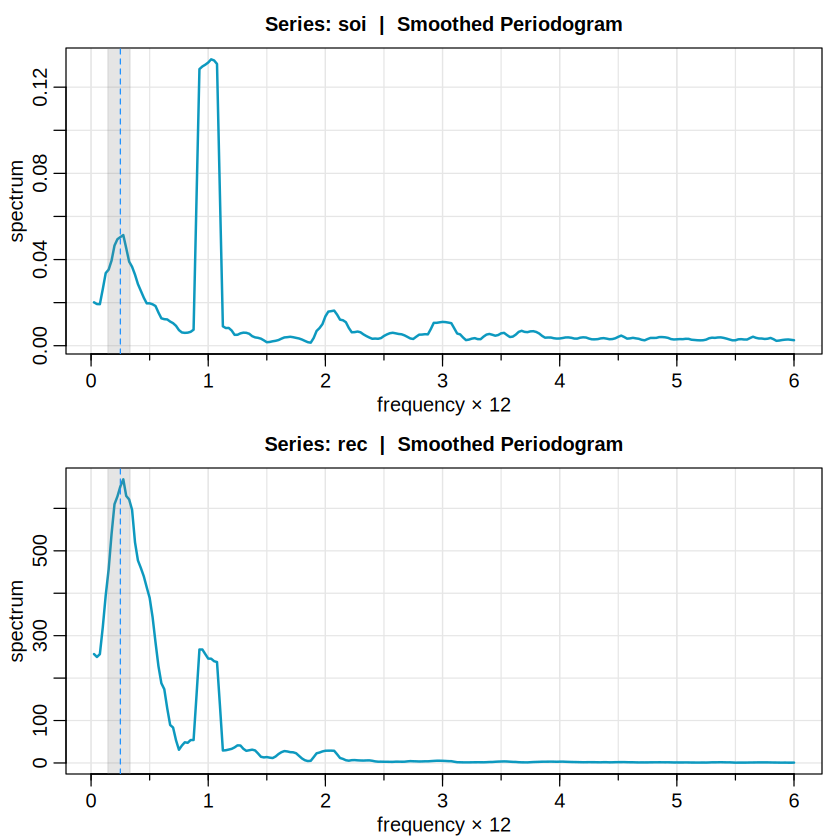

In [11]:
par(mfrow=c(2,1))
soi_ave = mvspec(soi, spans=9, col=rgb(.05,.6,.75), lwd=2)
rect(1/7,-1e5,1/3,1e5, density=NA, col=gray(.5,.2))
abline(v=.25, lty=2, col="dodgerblue")
rec_ave = mvspec(rec, spans=9, col=rgb(.05,.6,.75), lwd=2)
rect(1/7,-1e5,1/3,1e5, density=NA, col=gray(.5,.2))
abline(v=.25, lty=2, col="dodgerblue")
par(mfrow=c(1,1))
cat("SOI degrees of freedom:", soi_ave$df, "\n")
cat("SOI bandwidth (cycles/year):", soi_ave$bandwidth, "\n")

### Confidence intervals after smoothing

With a **uniform** $L$-ordinate average and no padding, a pointwise interval is

$$\boxed{\left[\frac{2L\bar f(\omega)}{\chi^2_{2L,0.975}},\;\frac{2L\bar f(\omega)}{\chi^2_{2L,0.025}}\right]}.$$

If the data are zero-padded from $n$ to $n'$, an approximate effective degrees of freedom is

$$\boxed{\nu\approx 2L\frac{n}{n'}}.$$

For general normalized smoothing weights $h_k$, replace $L$ by the effective width $L_h=1/\sum_k h_k^2$. These formulas are **approximations** that depend on the spectrum being roughly constant over the averaging band; tapering can alter the effective degrees of freedom further.

In [12]:
n_obs = length(soi)
n_fft = nextn(n_obs)
L = 9
df_uniform = 2*L*n_obs/n_fft
cat("Uniform 9-point approximation, adjusted df:", df_uniform, "\n")
cat("mvspec modified Daniell actual df:", soi_ave$df, "\n")
cat("Illustrative interval multiplier for df returned by mvspec:\n")
print(c(lower=soi_ave$df/qchisq(.975,soi_ave$df),
        upper=soi_ave$df/qchisq(.025,soi_ave$df)))

Uniform 9-point approximation, adjusted df: 16.9875 
mvspec modified Daniell actual df: 16.1067 
Illustrative interval multiplier for df returned by mvspec:
   lower    upper 
0.555605 2.308476 


**Read the multiplier:** At a selected plotted frequency with estimated spectrum $\hat f$, multiply $\hat f$ by the two printed factors to obtain the approximate 95% interval. These are **pointwise** intervals conditional on the smoothing assumptions. They should not be treated as family-wise significance guarantees for every peak selected after inspecting the complete spectrum.

**Executed interval calculation:** With the reported modified-Daniell degrees of freedom, the approximate 95% pointwise interval for a spectral ordinate $\hat f$ is **$[0.555605\,\hat f,\;2.308476\,\hat f]$**. The upper multiplier is more than four times the lower multiplier, emphasizing the asymmetry and remaining uncertainty after modest smoothing.

## 11. Harmonics of a non-sinusoidal cycle

A **fundamental frequency** is the repetition frequency of the overall pattern. **Harmonics** are integer multiples of it. A sawtooth waveform repeats every 20 observations but is not a pure sinusoid; its shape requires harmonic frequencies $2/20$, $3/20$, etc. A peak at a harmonic does not necessarily indicate an independent underlying cycle.

Fundamental frequency in cycles/observation: 0.05 
Period: 20 observations


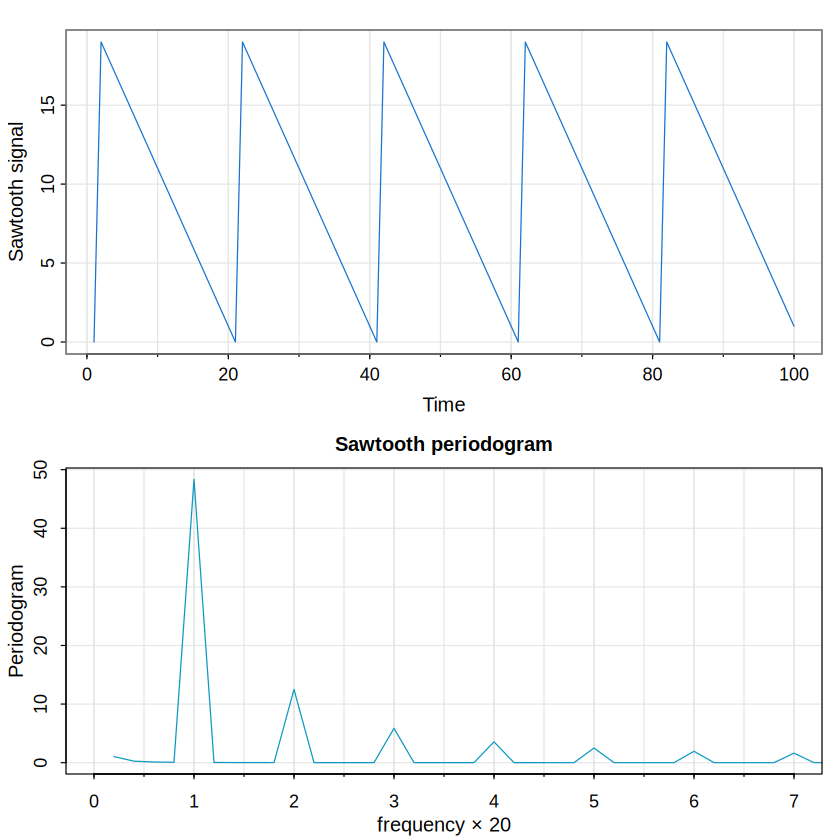

In [13]:
y = ts(rev(1:100 %% 20), freq=20)
par(mfrow=c(2,1))
tsplot(1:100, y, ylab="Sawtooth signal", col=4)
mvspec(y, main="Sawtooth periodogram", ylab="Periodogram", col=rgb(.05,.6,.75), xlim=c(0,7))
par(mfrow=c(1,1))
cat("Fundamental frequency in cycles/observation:", 1/20, "\n")
cat("Period:", 20, "observations\n")

**Graph interpretation:** The periodogram should show a series of peaks at whole-number multiples of 1 cycle per 20 observations on the annualized/seasonal frequency axis defined by the `ts` frequency. Harmonics encode the **sharp, asymmetric waveform**, not added random noise. Harmonic peak heights generally decrease as their frequencies increase.

## 12. Weighted smoothing and the modified Daniell kernel

Weighted spectral smoothing has the form

$$\boxed{\hat f(\omega_j)=\sum_{k=-m}^{m}h_k I(\omega_j+k/n)},\qquad h_k\ge0,\quad\sum h_k=1.$$

The **effective smoothing width** and approximate variance are

$$L_h=\frac1{\sum_k h_k^2},\qquad
\operatorname{Var}[\hat f(\omega)]\approx\frac{f^2(\omega)}{L_h}.$$

More concentrated central weights may preserve peaks better than a rectangular uniform average. A modified Daniell kernel reduces the two endpoint weights to half their interior value. Applying smoothing twice corresponds to convolving its weight sequences and generally creates a smoother bell-like kernel.

mDaniell(3,3) 
coef[-6] = 0.00694
coef[-5] = 0.02778
coef[-4] = 0.05556
coef[-3] = 0.08333
coef[-2] = 0.11111
coef[-1] = 0.13889
coef[ 0] = 0.15278
coef[ 1] = 0.13889
coef[ 2] = 0.11111
coef[ 3] = 0.08333
coef[ 4] = 0.05556
coef[ 5] = 0.02778
coef[ 6] = 0.00694

Sum of all symmetric weights: 1 
Effective width Lh: 9.23241 
Number of kernel weights: 13 


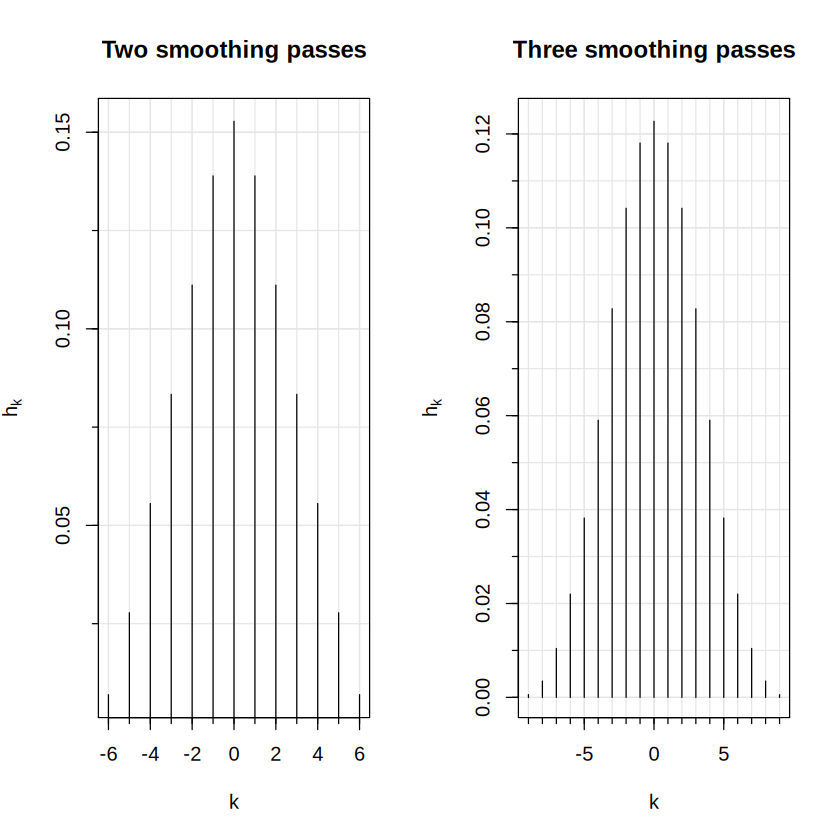

In [14]:
(dm = kernel("modified.daniell", c(3,3)))
par(mfrow=c(1,2))
plot(dm, ylab=expression(h[k]), main="Two smoothing passes", panel.first=Grid())
plot(kernel("modified.daniell", c(3,3,3)), ylab=expression(h[k]),
     main="Three smoothing passes", panel.first=Grid(nxm=5))
par(mfrow=c(1,1))
# A stats::kernel object stores h[0], h[1], ..., h[m], not both symmetric sides.
positive_lags = as.numeric(dm$coef)
full_weights = c(rev(positive_lags[-1]), positive_lags)
cat("Sum of all symmetric weights:", sum(full_weights), "\n")
cat("Effective width Lh:", 1/sum(full_weights^2), "\n")
cat("Number of kernel weights:", length(full_weights), "\n")

### Worked kernel calculation

The three-point modified Daniell weights are $(1/4,1/2,1/4)$. Applying them **twice** yields

$$\left(\frac1{16},\frac4{16},\frac6{16},\frac4{16},\frac1{16}\right).$$

The weights still sum to 1. Compared with a uniform 5-point window, the central ordinate receives more weight. For the two-pass $m=3$ kernel used below, the effective width is expected to be about $9.2324$ ordinates, so the padding-adjusted degrees of freedom are approximately $2(9.2324)(453/480)\approx17.43$.

**Implementation detail:** `stats::kernel` stores only the nonnegative-lag coefficients ($h_0,h_1,\ldots,h_m$). The opposite lags have identical weights, so calculate the full-kernel sum as $h_0+2\sum_{k=1}^m h_k$. Summing `dm$coef` alone incorrectly produces **0.576389**, and using only those stored coefficients in $1/\sum h_k^2$ incorrectly gives **15.1912**. Reconstructing both sides yields total weight **1** and an effective width of about **9.2324**. The corrected code cell must be rerun to replace its output.

## 13. Smoothed and tapered SOI/Recruitment spectra

Use two modified Daniell smoothing passes (`spans=c(7,7)`) with a 10% taper. **Tapering** gradually reduces the weight on the first and last portions of the time series before computing the DFT; it reduces spectral leakage from sharp observation-window boundaries.

Bandwidth: 0.231 | Degrees of Freedom: 15.61 | split taper: 10% 
Bandwidth: 0.231 | Degrees of Freedom: 15.61 | split taper: 10% 
SOI effective width Lh: 9.23241 
SOI bandwidth (cycles/year): 0.23081 
SOI df: 15.6103 


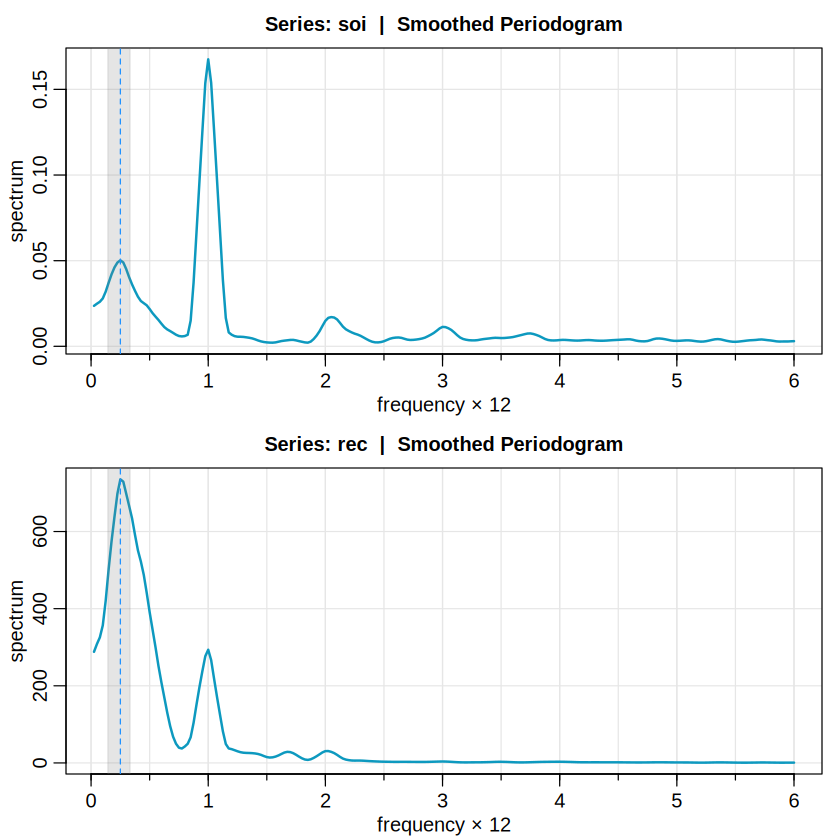

In [15]:
par(mfrow=c(2,1))
sois = mvspec(soi, spans=c(7,7), taper=.1, col=rgb(.05,.6,.75), lwd=2)
rect(1/7,-1e5,1/3,1e5, density=NA, col=gray(.5,.2))
abline(v=.25, lty=2, col="dodgerblue")
recs = mvspec(rec, spans=c(7,7), taper=.1, col=rgb(.05,.6,.75), lwd=2)
rect(1/7,-1e5,1/3,1e5, density=NA, col=gray(.5,.2))
abline(v=.25, lty=2, col="dodgerblue")
par(mfrow=c(1,1))
cat("SOI effective width Lh:", sois$Lh, "\n")
cat("SOI bandwidth (cycles/year):", sois$bandwidth, "\n")
cat("SOI df:", sois$df, "\n")

**Interpreting the graph:** The key comparison is whether multi-year and yearly peaks remain visible after smoothing. A persistent broad peak around $0.25$ cycles/year indicates power near a four-year timescale. A narrow peak near 1 cycle/year indicates a strong annual component. Smoothing reduces variance but may flatten or broaden a sharp spectral peak.

The theoretical conversion from effective width to displayed bandwidth is

$$B_{\mathrm{cycles/year}}=\frac{L_h}{n'}\times12.$$

**Observed spectral parameters:** With two modified-Daniell passes and a 10% taper, `mvspec()` reports effective width $L_h=9.23241$, bandwidth **0.23081 cycles/year**, and effective degrees of freedom **15.6103**. The degrees of freedom are lower than the untapered padding-based approximation **17.43**, because tapering also affects estimation uncertainty.

In [16]:
cat("Computed bandwidth conversion:", sois$Lh/nextn(length(soi))*12, "cycles/year\n")
cat("Package bandwidth:", sois$bandwidth, "cycles/year\n")

# sois$details is a matrix; convert it to a data frame before filtering by column.
spectral_details = as.data.frame(sois$details)
near_multi = spectral_details[spectral_details$frequency >= 1/7 &
                              spectral_details$frequency <= 1/3, , drop=FALSE]
near_annual = spectral_details[spectral_details$frequency >= .90 &
                               spectral_details$frequency <= 1.10, , drop=FALSE]

print(near_multi)
print(near_annual)
cat("Peak in 3-7 year band (cycles/year):",
    near_multi$frequency[which.max(near_multi$spectrum)], "\n")
cat("Peak near annual frequency (cycles/year):",
    near_annual$frequency[which.max(near_annual$spectrum)], "\n")

Computed bandwidth conversion: 0.23081 cycles/year
Package bandwidth: 0.23081 cycles/year
   frequency period spectrum
6      0.150 6.6667   0.0372
7      0.175 5.7143   0.0421
8      0.200 5.0000   0.0461
9      0.225 4.4444   0.0489
10     0.250 4.0000   0.0502
11     0.275 3.6364   0.0490
12     0.300 3.3333   0.0451
13     0.325 3.0769   0.0403
   frequency period spectrum
36     0.900 1.1111   0.0666
37     0.925 1.0811   0.0961
38     0.950 1.0526   0.1253
39     0.975 1.0256   0.1537
40     1.000 1.0000   0.1675
41     1.025 0.9756   0.1538
42     1.050 0.9524   0.1259
43     1.075 0.9302   0.0972
44     1.100 0.9091   0.0680
Peak in 3-7 year band (cycles/year): 0.25 
Peak near annual frequency (cycles/year): 1 


**Interpret the printed rows:** `frequency` is in cycles/year, `period` is in years/cycle, and `spectrum` is the estimated spectral power on the package's scale. A peak around $0.25$ corresponds to **4 years**, whereas a peak near 1 corresponds to **1 year**. The exact maximizing bins and their power values are printed from the executed data rather than assumed in advance.

**Numerical peak interpretation:** In the 3–7-year band, the largest printed SOI estimate is **0.0502** at **0.25 cycles/year**, corresponding to a **4-year period**. Around the seasonal frequency, it is **0.1675** at **1 cycle/year**. The seasonal peak is roughly **3.34 times** the estimated height of the four-year peak **on this plotted spectral scale**; this does not mean the annual cycle explains 3.34 times as much variance, because integrated *area over frequency* is needed for variance comparisons. Both peaks occur at the expected frequency bins, but the spectrum also extends to neighboring bins.

## 14. Tapering and spectral leakage

For an untapered finite record, the spectral window has the form

$$W_n(\omega)=\frac{\sin^2(n\pi\omega)}{n\sin^2(\pi\omega)},\qquad W_n(0)=n.$$

The sidelobes of this window allow power from one frequency to contaminate other frequencies—**spectral leakage**. A full cosine taper is

$$u_t=\frac12\left[1+\cos\left(\frac{2\pi(t-\bar t)}{n}\right)\right],\qquad \bar t=(n+1)/2.$$

It down-weights observations near the beginning and end. Suppressing leakage may widen the main lobe, reducing the ability to distinguish two extremely close peaks. Consequently tapering trades some resolution for less sidelobe contamination.

Peak at annual bin, no taper: 0.158185 
Peak at annual bin, 20% taper: 0.166459 
Peak at annual bin, 50% taper: 0.164238 


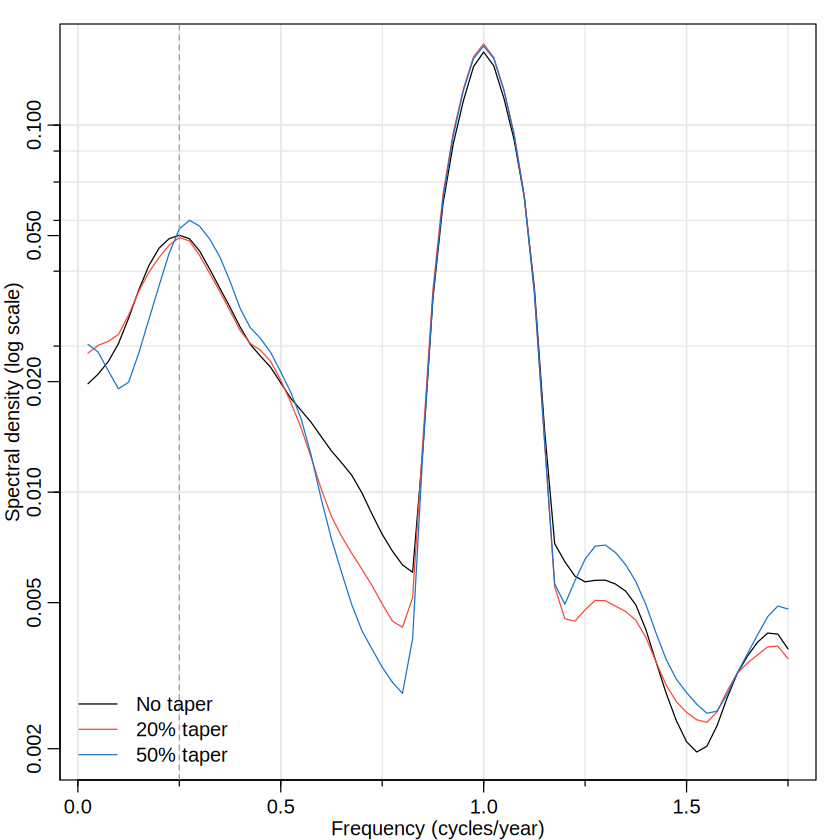

In [17]:
par(mar=c(2.5,2.5,1,1), mgp=c(1.5,.6,0))
s0  = mvspec(soi, spans=c(7,7), plot=FALSE)
s20 = mvspec(soi, spans=c(7,7), taper=.2, plot=FALSE)
s50 = mvspec(soi, spans=c(7,7), taper=.5, plot=FALSE)
plot(s0$freq[1:70], s0$spec[1:70], log="y", type="l", ylab="Spectral density (log scale)",
     xlab="Frequency (cycles/year)", panel.first=Grid())
lines(s20$freq[1:70], s20$spec[1:70], col=2)
lines(s50$freq[1:70], s50$spec[1:70], col=4)
abline(v=.25, lty=2, col=8)
legend("bottomleft", legend=c("No taper", "20% taper", "50% taper"),
       lty=1, col=c(1,2,4), bty="n")
cat("Peak at annual bin, no taper:", s0$spec[which.min(abs(s0$freq-1))], "\n")
cat("Peak at annual bin, 20% taper:", s20$spec[which.min(abs(s20$freq-1))], "\n")
cat("Peak at annual bin, 50% taper:", s50$spec[which.min(abs(s50$freq-1))], "\n")

**Graph interpretation:** At each frequency, compare the estimated log spectra for different tapers. Tapering can reduce apparent spectral power between strong peaks when that power comes from leakage, but a greater taper does not automatically produce a better estimate. Differences in peak heights partly reflect changed spectral windows, not changes in the underlying observations.

For practical peak inference, prespecification of frequencies, an appropriate null spectrum, and attention to multiple-frequency testing are important; a higher peak after tuning does not establish significance by itself.

**Observed taper comparison:** At the annual-frequency bin, the reported estimates are **0.158185** (no taper), **0.166459** (20% taper), and **0.164238** (50% taper). The 20% taper gives the highest ordinate of these three *at that particular bin*, but the change is small and does not establish that 20% is the optimal taper overall. Assess leakage and neighboring frequencies, not just peak height.

## 15. Parametric spectral estimation: AR model

Nonparametric estimation smooths the periodogram without imposing a specific ARMA order. **Parametric spectral estimation** instead fits a stochastic model and substitutes its fitted coefficients into the theoretical spectrum. For an AR($p$) process,

$$x_t-\mu=\sum_{k=1}^p\phi_k(x_{t-k}-\mu)+w_t,\qquad E(w_t)=0,\quad\operatorname{Var}(w_t)=\sigma_w^2,$$

$$\boxed{\hat f_{AR}(\omega)=\frac{\hat\sigma_w^2}{\left|1-\sum_{k=1}^p\hat\phi_k e^{-2\pi i\omega k}\right|^2}}.$$

A pronounced peak occurs when the fitted AR polynomial has a small magnitude at a frequency. AIC and BIC balance fit and model complexity; they are **relative** criteria, not a guarantee that an estimated spectrum is correct. The selected order can change with the data, estimation method, or maximum order searched.


Call:
ar(x = soi, order.max = 30)

Coefficients:
     1       2       3       4       5       6       7       8       9      10  
 0.424   0.080   0.141   0.075  -0.045  -0.082  -0.069  -0.064   0.016   0.110  
    11      12      13      14      15  
 0.166   0.148   0.023  -0.181  -0.141  

Order selected 15  sigma^2 estimated as  0.0758

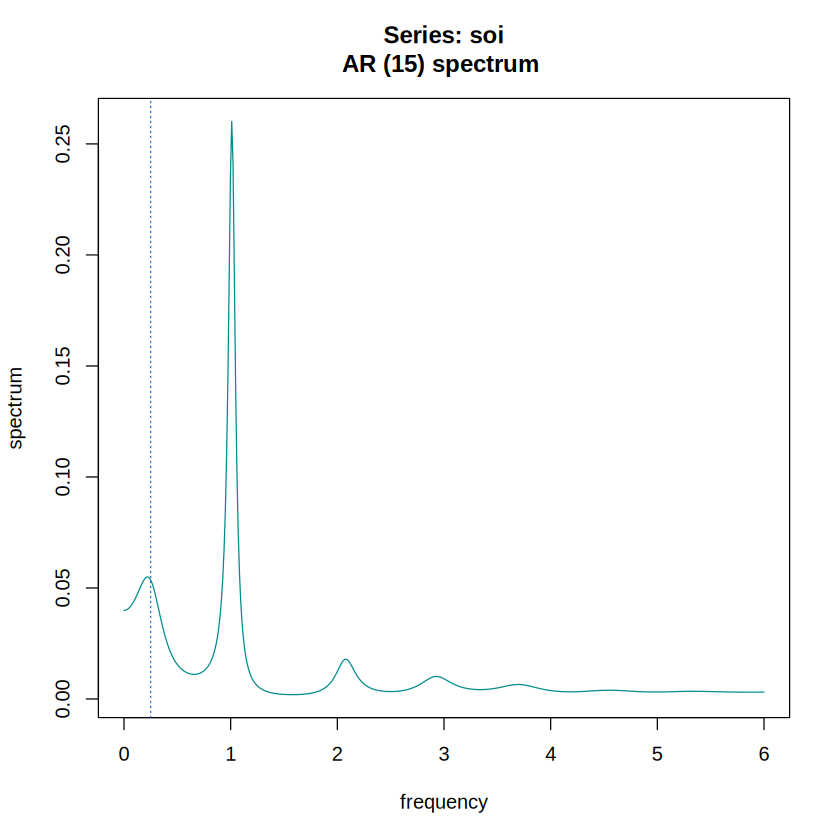

AIC-selected AR order: 15 


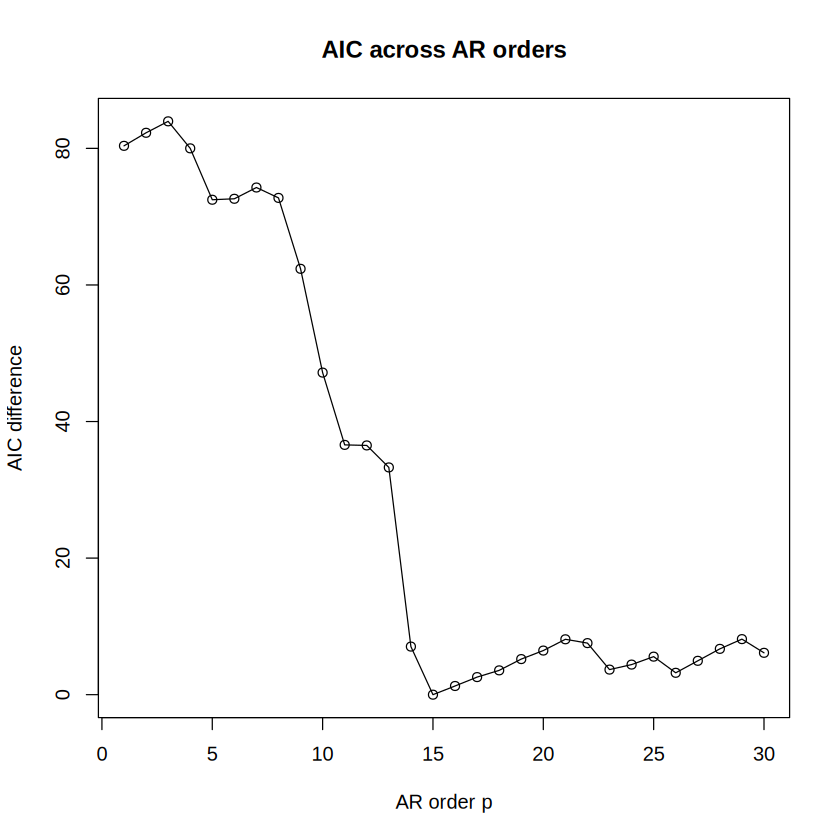

In [18]:
spaic = spec.ar(soi, log="no", col="cyan4")
abline(v=frequency(soi)/48, lty="dotted", col=4)
(soi.ar = ar(soi, order.max=30))
plot(1:30, soi.ar$aic[-1], type="o", xlab="AR order p", ylab="AIC difference",
     main="AIC across AR orders")
cat("AIC-selected AR order:", soi.ar$order, "\n")

**Interpretation:** `spec.ar()` estimates a smooth spectrum constrained by an autoregressive model. Compare peaks near $0.25$ and $1$ cycles/year with the nonparametric spectra. The `ar()` order is the minimizing order **within the examined candidates**; its numerical value should be read from the execution rather than assumed. AIC differences near zero mean neighboring model orders have similar support.

**Observed selection:** The `ar()` run selects **AR(15)** by AIC within the tested orders up to 30. This is a relatively high-order dependence model whose spectrum can reproduce narrow periodic features; verify the model residuals before using the fitted AR order for substantive interpretation or forecasting.

## 16. Compare AIC, BIC, and innovation variance across AR orders

For $n$ observations and $p$ AR coefficients, the per-observation criteria used here are

$$\mathrm{AIC}(p)=\log\hat\sigma_p^2+\frac{n+2p}{n},\qquad
\mathrm{BIC}(p)=\log\hat\sigma_p^2+\frac{p\log n}{n}.$$

These forms omit constants shared across model orders. The extra $1$ in the AIC expression is constant across $p$, so it does not affect the minimizing order. The package's `ar()` AIC output can use a different constant baseline. **Compare scores within one consistently computed column, not raw values from differing conventions.**

Best AIC order: 15 | Best BIC order: 15 
    p  variance      AIC      BIC
15 15 0.0757524 -1.51406 -2.37777


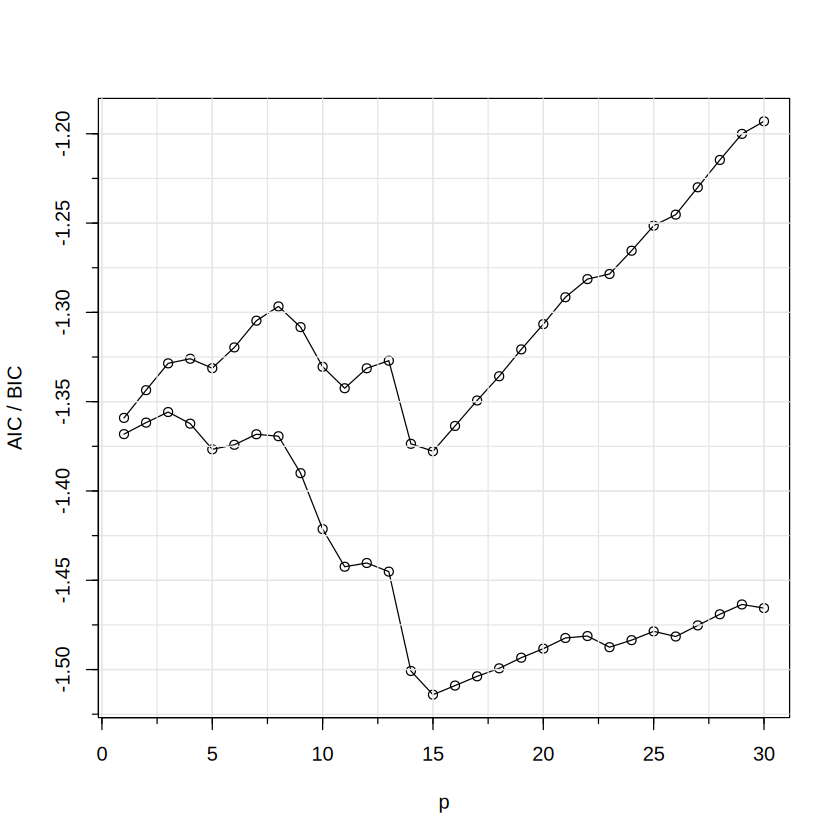

In [19]:
n = length(soi)
AIC = BIC = sigma2 = numeric(30)
for (k in 1:30) {
  sigma2[k] = ar(soi, order=k, aic=FALSE)$var.pred
  BIC[k] = log(sigma2[k]) + k*log(n)/n
  AIC[k] = log(sigma2[k]) + (n+2*k)/n
}

# Shift BIC upward by one unit for clear display only.
IC = cbind(AIC, BIC+1)
ts.plot(IC, type="o", xlab="p", ylab="AIC / BIC")
Grid()

cat("Best AIC order:", which.min(AIC), "| Best BIC order:", which.min(BIC), "\n")
print(data.frame(p=1:30, variance=sigma2, AIC=AIC, BIC=BIC)[unique(c(which.min(AIC), which.min(BIC))), ])

**Numerical interpretation:** Each additional AR lag tends to reduce fitted innovation variance but adds a penalty. AIC penalizes an added coefficient by about $2/n$; BIC uses $\log(n)/n$, which is larger for $n>e^2$. If both criteria select the same order, that provides some agreement **within the tested model class**, not confirmation of the exact physical oscillatory mechanism. Compare candidate fits with residual diagnostics before choosing a forecasting model.

**Observed criteria:** For the candidate orders $p=1,\ldots,30$, **both AIC and BIC select $p=15$**, with estimated innovation variance **0.0757524**, AIC **−1.51406**, and BIC **−2.37777** on the specific scales defined above. The plotted BIC curve is shifted upward by $1$ solely for display; the printed BIC values and model selection use the unshifted criterion. **Only differences within the same criterion matter**. Agreement does not eliminate the need to check model adequacy.

## 17. Cross-spectra and coherence between two time series

The **cross-covariance** measures lagged dependence between two jointly stationary series:

$$\gamma_{xy}(h)=E[(x_{t+h}-\mu_x)(y_t-\mu_y)].$$

Its Fourier transform is the potentially complex-valued **cross-spectrum**:

$$f_{xy}(\omega)=\sum_{h=-\infty}^{\infty}\gamma_{xy}(h)e^{-2\pi i\omega h}
=c_{xy}(\omega)-i\,q_{xy}(\omega).$$

The real part $c_{xy}$ is the **cospectrum**; the negative imaginary part involves the **quadspectrum** $q_{xy}$. Their magnitudes and phase contain information about shared frequency-specific variation and lead-lag behavior.

The **squared coherence** is

$$\boxed{C^2_{yx}(\omega)=\frac{|f_{yx}(\omega)|^2}{f_{xx}(\omega)f_{yy}(\omega)}}\qquad(0\le C^2_{yx}\le1).$$

Values near 1 indicate a strong **linear relationship at that frequency**; values near 0 indicate weak *linear* frequency-specific association. Coherence is not a causal measure and by itself does not specify which series leads.

## 18. Three-point moving average: theoretical coherence

For the centered linear filter

$$y_t=\frac{x_{t-1}+x_t+x_{t+1}}3,$$

its frequency response is

$$H(\omega)=\frac{1+2\cos(2\pi\omega)}3.$$

Thus

$$f_{yy}(\omega)=|H(\omega)|^2f_{xx}(\omega),\qquad
f_{xy}(\omega)=H(\omega)f_{xx}(\omega),$$

and, whenever $H(\omega)\ne0$ and $f_{xx}(\omega)>0$,

$$C^2_{yx}(\omega)=\frac{|H(\omega)f_{xx}(\omega)|^2}{f_{xx}(\omega)|H(\omega)|^2 f_{xx}(\omega)}=1.$$

**Exception:** At frequencies where $H(\omega)=0$, $f_{yy}(\omega)=0$ and the ratio becomes $0/0$, so ordinary coherence is undefined there. A finite-record sample estimate may also be less than 1 due to edge handling or noise.

Gain at zero frequency: 1 
Gain at 1/3: 2.19128e-32 
Gain at Nyquist frequency: 0.111111 


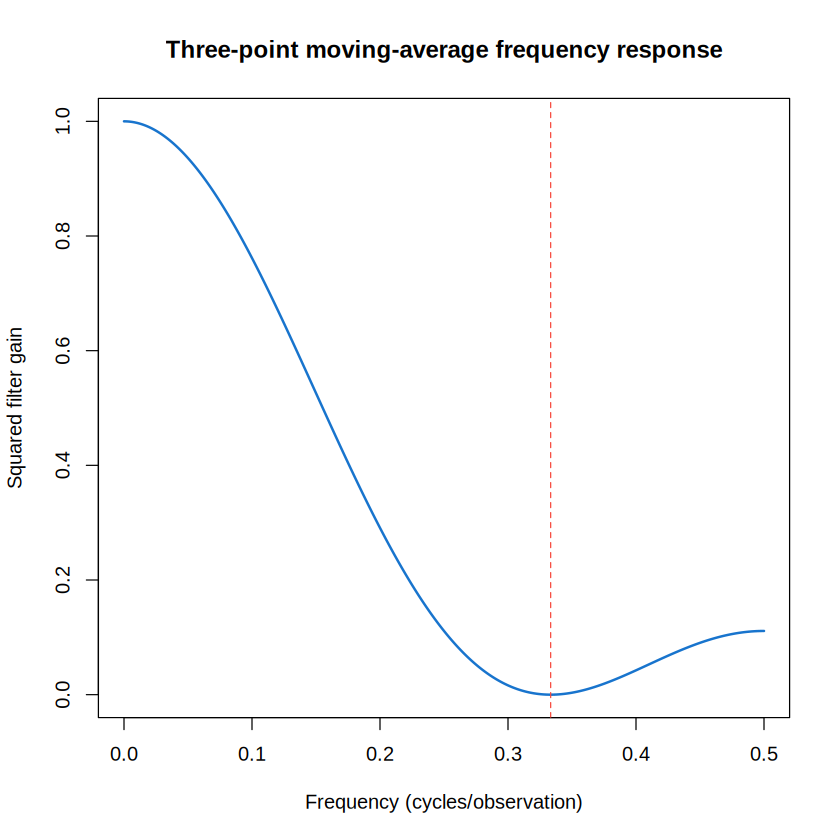

In [20]:
f = seq(0,.5,by=.001)
H = (1+2*cos(2*pi*f))/3
plot(f, H^2, type="l", lwd=2, col=4,
     xlab="Frequency (cycles/observation)", ylab="Squared filter gain",
     main="Three-point moving-average frequency response")
abline(v=1/3, col=2, lty=2)
cat("Gain at zero frequency:", ((1+2*cos(0))/3)^2, "\n")
cat("Gain at 1/3:", ((1+2*cos(2*pi/3))/3)^2, "\n")
cat("Gain at Nyquist frequency:", ((1+2*cos(pi))/3)^2, "\n")

**Interpretation:** The three-point average completely suppresses a sinusoid at $\omega=1/3$ cycles/observation, so there is no output power at that exact frequency. Away from these zeros, a deterministic noiseless linear filter has theoretical coherence equal to 1 even where the filter strongly attenuates power. Therefore, **high coherence alone is not evidence of high output power**.

## 19. Estimated SOI–Recruitment coherence

Estimate the spectral matrix using a Daniell kernel. For a uniform smoother with $L>1$ independent averaged frequencies, a rough null statistic for **zero coherence at a prespecified frequency** is

$$F=\frac{\hat C^2(\omega)}{1-\hat C^2(\omega)}(L-1)
\ \overset{\cdot}{\sim}\ F_{2,\,2L-2}.$$

With zero-padding and adjusted degrees of freedom $\nu$, the approximate denominator degrees of freedom become $\nu-2$. For a significance threshold $\alpha$,

$$\boxed{C_\alpha=\frac{F_{2,\nu-2;1-\alpha}}{(L-1)+F_{2,\nu-2;1-\alpha}}}.$$

This heuristic threshold is pointwise, approximate, and sensitive to the effective smoothing bandwidth. Simultaneous testing across many frequencies requires an additional multiple-comparisons strategy.

Estimated effective df: 35.8625 
F critical value at alpha=0.001: 8.52979 
Approximate squared-coherence threshold: 0.321517 


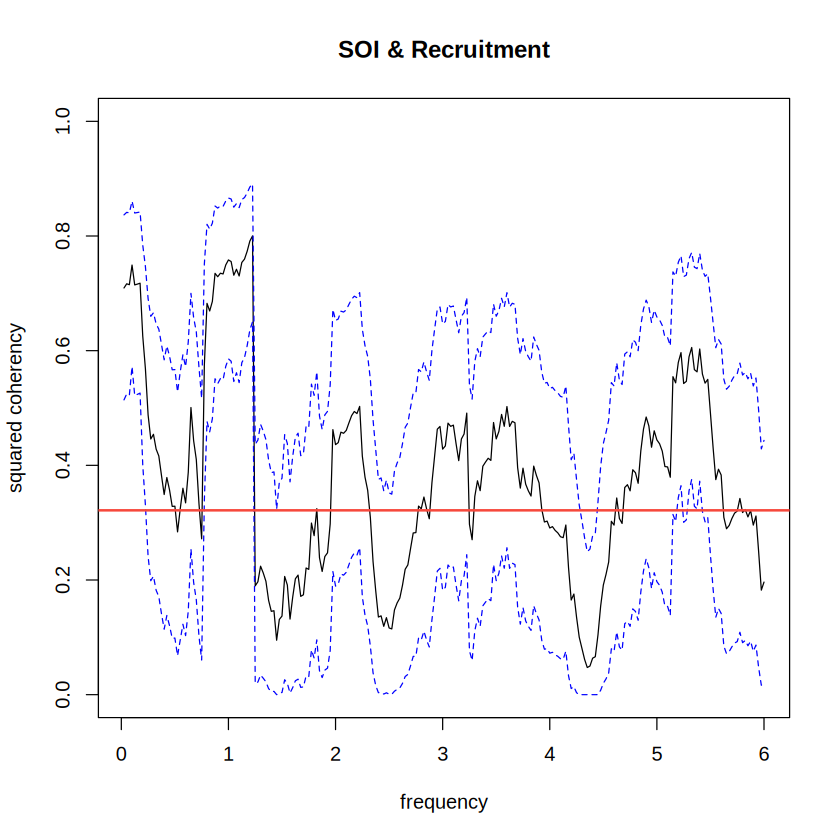

In [21]:
sr = mvspec(cbind(soi,rec), kernel("daniell",9), plot=FALSE)
cat("Estimated effective df:", sr$df, "\n")
L = 19
Fcrit = qf(.999, 2, sr$df-2)
Ccrit = Fcrit/(L-1+Fcrit)
cat("F critical value at alpha=0.001:", Fcrit, "\n")
cat("Approximate squared-coherence threshold:", Ccrit, "\n")
plot(sr, plot.type="coh", ci.lty=2, main="SOI & Recruitment")
abline(h=Ccrit, col=2, lwd=2)

**Interpret the coherence plot:** The horizontal line is an approximate **pointwise** threshold at $\alpha=0.001$, not proof of a connection at every frequency over the curve. Look especially near $0.25$ cycles/year (multi-year El Niño range) and 1 cycle/year (seasonal cycle). Values above the line suggest shared linear oscillatory behavior, but do not establish that SOI causes Recruitment changes or identify direction of influence. High coherence where both autospectra are small can also be practically unimportant.

**Calculated cutoff:** The fitted coherence analysis reports adjusted degrees of freedom **35.8625**, $F_{crit}=**8.52979**$, and squared-coherence cutoff **0.321517** for the specified approximate $\alpha=0.001$ comparison. Coherence values above this cutoff at prespecified frequencies warrant investigation, but the curve alone cannot establish causation or a simultaneous significance claim over all inspected frequencies.

## 20. Direct comparison of spectral estimation methods

A good spectral analysis uses complementary views: an unsmoothed periodogram to find candidate narrow peaks; smoothed/tapered spectra to reduce variance and leakage; an AR-based spectrum to check whether the same frequencies appear under a parametric model; and coherence to examine whether two series share frequency-specific linear variation. No single spectral plot replaces stationarity assessment, uncertainty checks, or residual diagnostics.

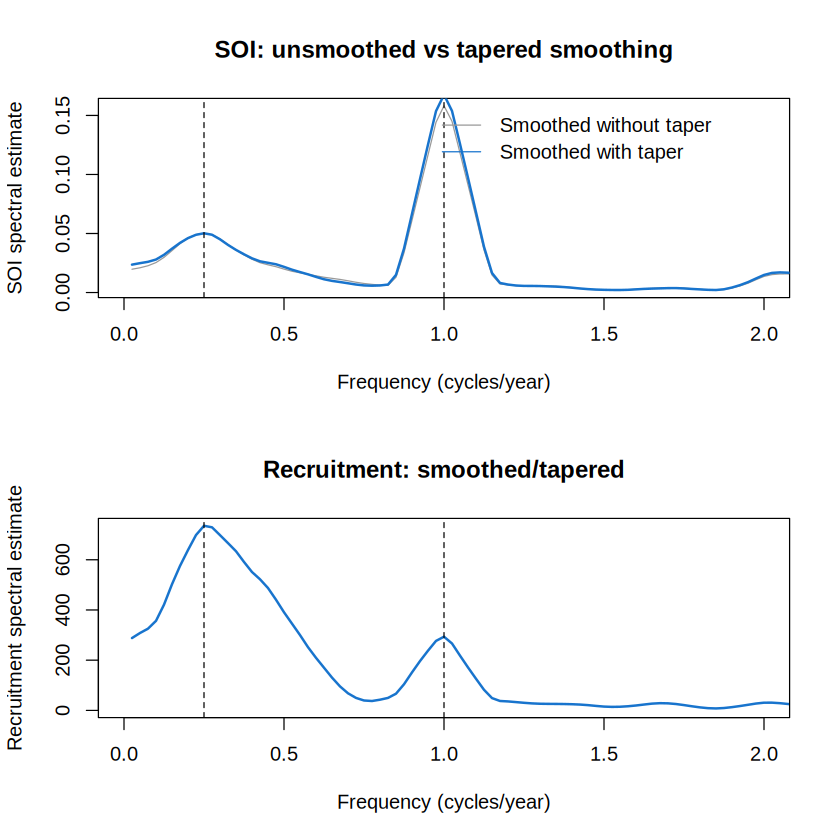

In [22]:
par(mfrow=c(2,1))
plot(s0$freq, s0$spec, type="l", col=gray(.6), xlim=c(0,2),
     xlab="Frequency (cycles/year)", ylab="SOI spectral estimate",
     main="SOI: unsmoothed vs tapered smoothing")
lines(sois$freq, sois$spec, col=4, lwd=2)
abline(v=c(.25,1), lty=2)
legend("topright", c("Smoothed without taper", "Smoothed with taper"),
       lty=1, col=c(gray(.6),4), bty="n")
plot(recs$freq, recs$spec, type="l", col=4, lwd=2, xlim=c(0,2),
     xlab="Frequency (cycles/year)", ylab="Recruitment spectral estimate",
     main="Recruitment: smoothed/tapered")
abline(v=c(.25,1), lty=2)
par(mfrow=c(1,1))

**Reading the comparison:** A peak that persists across both tapered and untapered estimates is less likely to be an artifact of one spectral window. The two series have different variance scales, so the most meaningful comparison is the **location and width** of peaks rather than raw peak-height equality. Repeated analysis across reasonable smoothing widths is more informative than choosing the curve with the most dramatic peaks.

## Key mathematical relationships

| Quantity | Expression | Practical meaning |
|---|---|---|
| Fourier frequency | $\omega_j=j/n$ | Cycles per observation |
| Period | $T=1/\omega$ | Observations per cycle |
| DFT | $n^{-1/2}\sum_t x_t e^{-2\pi i\omega_jt}$ | Fourier coefficient |
| Periodogram | $I(\omega_j)=|d(\omega_j)|^2$ | Raw frequency power |
| Smoothed spectrum | $\hat f=\sum_kh_kI_k$ | Lower-variance spectral estimate |
| Effective width | $L_h=(\sum_kh_k^2)^{-1}$ | Rough number of ordinates pooled |
| Approximate df | $\nu\approx2L_h n/n'$ | Confidence-interval adjustment for padding |
| AR spectrum | $\sigma_w^2/|\phi(e^{-2\pi i\omega})|^2$ | Model-based frequency power |
| Squared coherence | $|f_{yx}|^2/(f_{xx}f_{yy})$ | Shared linear variation at frequency |

**Statistical limitation:** Spectral estimators generally rely on stationarity or appropriate detrending, and their confidence intervals depend on approximations. The printed R results and actual peaks should be interpreted after execution rather than assuming any simulated or estimated value must exactly match a historical example.